In [5]:
from pathlib import Path
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from loguru import logger

# Cấu hình hiển thị
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

BASE_DIR = Path("..")
GOLD_DIR = BASE_DIR / "data" / "3_gold"
GOLD_PATH = GOLD_DIR / "weekly_demand_features_calendar_fixed.parquet"

# Nạp dữ liệu
df_gold = pl.read_parquet(GOLD_PATH)

logger.info(f"Dữ liệu Gold v4: {df_gold.height:,} dòng | {len(df_gold.columns)} cột")
print("\nKiểu dữ liệu và thống kê sơ bộ:")
display(df_gold.describe())

2026-11-06 14:14:49.725 | INFO     | __main__:<module>:19 - Dữ liệu Gold v4: 301,631 dòng | 20 cột



Kiểu dữ liệu và thống kê sơ bộ:


statistic,Week_Start,StockCode,Weekly_Demand,Weekly_Revenue,Avg_UnitPrice,Description,Target_Demand_Weekly,Target_Week_Start,Lag_1W,Lag_2W,Lag_4W,Rolling_Mean_4W,Rolling_Std_4W,Month,Quarter,Year,Is_Peak_Season,Demand_Trend_Ratio,Demand_CV,Price_Ratio_Vs_Avg
str,str,str,f64,f64,f64,str,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""","""301631""","""301631""",301631.0,301631.0,178509.0,"""301631""",301631.0,"""301631""",301631.0,301631.0,301631.0,301631.0,301631.0,301631.0,301631.0,301631.0,301631.0,301631.0,301631.0,98789.0
"""null_count""","""0""","""0""",0.0,0.0,123122.0,"""0""",0.0,"""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,202842.0
"""mean""","""2010-12-08 23:55:42.488007""",null,33.652015,61.523168,3.94736,null,34.157398,"""2010-12-15 23:55:42.488007""",33.488832,33.696755,34.068544,33.755178,28.256216,6.305479,2.448306,2010.456293,0.133925,0.647104,0.674745,1.028089
"""std""",null,null,144.339322,280.016561,36.397573,null,150.723107,null,143.780989,144.476206,197.218037,104.231092,135.812253,3.330537,1.098225,0.512916,0.340573,0.819107,0.485265,1.971422
"""min""","""2009-12-28 00:00:00""","""10002""",0.0,0.0,0.001,"""*USB Office Mirror Ball""",0.0,"""2010-01-04 00:00:00""",0.0,0.0,0.0,0.0,0.0,1.0,1.0,2009.0,0.0,0.0,0.0,0.001841
"""25%""","""2010-06-21 00:00:00""",null,0.0,0.0,1.25,null,0.0,"""2010-06-28 00:00:00""",0.0,0.0,0.0,0.5,0.57735,3.0,1.0,2010.0,0.0,0.0,0.380059,0.897088
"""50%""","""2010-12-06 00:00:00""",null,2.0,5.79,2.196667,null,2.0,"""2010-12-13 00:00:00""",2.0,2.0,2.0,5.0,5.439056,6.0,2.0,2010.0,0.0,0.333333,0.660366,0.999976
"""75%""","""2011-05-30 00:00:00""",null,22.0,40.26,4.21,null,23.0,"""2011-06-06 00:00:00""",22.0,22.0,23.0,26.75,21.328776,9.0,3.0,2011.0,0.0,1.052632,0.997023,1.093321
"""max""","""2011-11-28 00:00:00""","""TEST001""",19165.0,40278.52,13541.33,"""ZINC WIRE SWEETHEART LETTER TR…",19165.0,"""2011-12-05 00:00:00""",19165.0,19165.0,74215.0,18553.75,37107.5,12.0,4.0,2011.0,1.0,3.997757,1.999892,612.689447


In [10]:
# ============================================================
# 1. DATASET OVERVIEW
# ============================================================

logger.info("Starting Data Understanding - Phase 1")

print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

print(f"Total Rows       : {df_gold.height:,}")
print(f"Total Columns    : {df_gold.width}")
print(f"Memory Usage     : {df_gold.estimated_size('mb'):.2f} MB")

print("\n===== SCHEMA =====")
for col, dtype in df_gold.schema.items():
    print(f"{col:<30} {dtype}")

print("\n===== FIRST 5 ROWS =====")
display(df_gold.head(5))

print("\n===== RANDOM SAMPLE =====")
display(df_gold.sample(n=min(5, df_gold.height), seed=42))

2026-11-06 14:20:56.928 | INFO     | __main__:<module>:5 - Starting Data Understanding - Phase 1


DATASET OVERVIEW
Total Rows       : 301,631
Total Columns    : 20
Memory Usage     : 44.45 MB

===== SCHEMA =====
Week_Start                     Datetime(time_unit='us', time_zone=None)
StockCode                      String
Weekly_Demand                  Int64
Weekly_Revenue                 Float64
Avg_UnitPrice                  Float64
Description                    String
Target_Demand_Weekly           Int64
Target_Week_Start              Datetime(time_unit='us', time_zone=None)
Lag_1W                         Int64
Lag_2W                         Int64
Lag_4W                         Int64
Rolling_Mean_4W                Float64
Rolling_Std_4W                 Float64
Month                          Int8
Quarter                        Int8
Year                           Int32
Is_Peak_Season                 Int32
Demand_Trend_Ratio             Float64
Demand_CV                      Float64
Price_Ratio_Vs_Avg             Float64

===== FIRST 5 ROWS =====


Week_Start,StockCode,Weekly_Demand,Weekly_Revenue,Avg_UnitPrice,Description,Target_Demand_Weekly,Target_Week_Start,Lag_1W,Lag_2W,Lag_4W,Rolling_Mean_4W,Rolling_Std_4W,Month,Quarter,Year,Is_Peak_Season,Demand_Trend_Ratio,Demand_CV,Price_Ratio_Vs_Avg
datetime[μs],str,i64,f64,f64,str,i64,datetime[μs],i64,i64,i64,f64,f64,i8,i8,i32,i32,f64,f64,f64
2009-12-28 00:00:00,"""10002""",0,0.0,null,"""INFLATABLE POLITICAL GLOBE""",15,2010-01-04 00:00:00,14,37,141,54.0,58.759396,12,4,2009,1,0.254545,1.068353,null
2010-01-04 00:00:00,"""10002""",15,12.75,0.85,"""INFLATABLE POLITICAL GLOBE""",191,2010-01-11 00:00:00,0,14,24,18.75,15.649814,1,1,2010,0,0.0,0.792396,null
2010-01-11 00:00:00,"""10002""",191,162.35,0.85,"""INFLATABLE POLITICAL GLOBE""",41,2010-01-18 00:00:00,15,0,37,16.5,15.286159,1,1,2010,0,0.857143,0.873495,null
2010-01-18 00:00:00,"""10002""",41,35.66,1.012,"""INFLATABLE POLITICAL GLOBE""",44,2010-01-25 00:00:00,191,15,14,55.0,90.924877,1,1,2010,0,3.410714,1.623659,null
2010-01-25 00:00:00,"""10002""",44,38.21,0.985,"""INFLATABLE POLITICAL GLOBE""",16,2010-02-01 00:00:00,41,191,0,61.75,87.815621,1,1,2010,0,0.653386,1.399452,null



===== RANDOM SAMPLE =====


Week_Start,StockCode,Weekly_Demand,Weekly_Revenue,Avg_UnitPrice,Description,Target_Demand_Weekly,Target_Week_Start,Lag_1W,Lag_2W,Lag_4W,Rolling_Mean_4W,Rolling_Std_4W,Month,Quarter,Year,Is_Peak_Season,Demand_Trend_Ratio,Demand_CV,Price_Ratio_Vs_Avg
datetime[μs],str,i64,f64,f64,str,i64,datetime[μs],i64,i64,i64,f64,f64,i8,i8,i32,i32,f64,f64,f64
2010-04-19 00:00:00,"""84990""",0,0.0,null,"""60 GOLD AND SILVER FAIRY CAKE …",30,2010-04-26 00:00:00,0,8,198,63.75,92.037583,4,2,2010,0,0.0,1.42143,null
2010-08-30 00:00:00,"""22057""",8,11.92,1.49,"""CERAMIC PLATE STRAWBERRY DESIG…",2,2010-09-06 00:00:00,276,29,11,79.0,131.876205,8,3,2010,0,3.45,1.648453,null
2010-06-07 00:00:00,"""90209A""",0,0.0,null,"""PURPLE ENAMEL+GLASS HAIR COMB""",0,2010-06-14 00:00:00,0,0,0,0.0,0.0,6,2,2010,0,0.0,0.0,null
2010-02-22 00:00:00,"""82597""",6,12.6,2.1,"""BOMBS AWAY METAL SIGN""",68,2010-03-01 00:00:00,41,7,27,26.5,14.271183,2,1,2010,0,1.490909,0.518952,0.891256
2011-01-03 00:00:00,"""84913A""",17,62.28,3.618,"""SOFT PINK ROSE TOWEL""",20,2011-01-10 00:00:00,0,4,41,13.25,18.786076,1,1,2011,0,0.0,1.318321,null


In [11]:
# ============================================================
# 3. DATA QUALITY OVERVIEW
# ============================================================

quality_report = []

for col in df_gold.columns:
    null_count = df_gold[col].null_count()
    unique_count = df_gold[col].n_unique()

    quality_report.append({
        "Column": col,
        "Null_Count": null_count,
        "Missing_Rate": round(null_count / df_gold.height * 100, 2),
        "Unique_Count": unique_count
    })

quality_report = pl.DataFrame(quality_report)

display(
    quality_report.sort("Missing_Rate", descending=True)
)

Column,Null_Count,Missing_Rate,Unique_Count
str,i64,f64,i64
"""Price_Ratio_Vs_Avg""",202842,67.25,78550
"""Avg_UnitPrice""",123122,40.82,21520
"""Week_Start""",0,0.0,101
"""StockCode""",0,0.0,4501
"""Weekly_Demand""",0,0.0,1477
…,…,…,…
"""Quarter""",0,0.0,4
"""Year""",0,0.0,3
"""Is_Peak_Season""",0,0.0,2


In [12]:
# ============================================================
# PRICE MISSING VALUE DIAGNOSIS
# ============================================================

price_audit = df_gold.select([
    pl.len().alias("Total_Rows"),
    (pl.col("Weekly_Demand") == 0).sum().alias("Zero_Demand"),
    pl.col("Weekly_Revenue").null_count().alias("Revenue_Null"),
    pl.col("Avg_UnitPrice").null_count().alias("Price_Null"),
    pl.col("Price_Ratio_Vs_Avg").null_count().alias("Ratio_Null"),
    (
        pl.col("Avg_UnitPrice").is_null() &
        pl.col("Price_Ratio_Vs_Avg").is_null()
    ).sum().alias("Both_Null"),
    (
        pl.col("Avg_UnitPrice").is_not_null() &
        pl.col("Price_Ratio_Vs_Avg").is_null()
    ).sum().alias("Only_Ratio_Null"),
    (
        pl.col("Avg_UnitPrice").is_null() &
        pl.col("Price_Ratio_Vs_Avg").is_not_null()
    ).sum().alias("Only_Price_Null")
])

display(price_audit)

Total_Rows,Zero_Demand,Revenue_Null,Price_Null,Ratio_Null,Both_Null,Only_Ratio_Null,Only_Price_Null
u32,u32,u32,u32,u32,u32,u32,u32
301631,123122,0,123122,202842,123122,79720,0


In [13]:
display(
    df_gold.select([
        pl.col("Target_Demand_Weekly").min().alias("Target_Min"),
        pl.col("Target_Demand_Weekly").max().alias("Target_Max"),
        pl.col("Target_Demand_Weekly").mean().alias("Target_Mean"),
        pl.col("Target_Demand_Weekly").median().alias("Target_Median"),
        pl.col("Target_Demand_Weekly").std().alias("Target_Std"),
        (pl.col("Target_Demand_Weekly") == 0).sum().alias("Zero_Target"),
        (pl.col("Target_Demand_Weekly") < 0).sum().alias("Negative_Target")
    ])
)

Target_Min,Target_Max,Target_Mean,Target_Median,Target_Std,Zero_Target,Negative_Target
i64,i64,f64,f64,f64,u32,u32
0,19165,34.157398,2.0,150.723107,119998,0


In [14]:
missing_by_year = (
    df_gold.group_by("Year")
    .agg([
        pl.len().alias("Total_Rows"),
        pl.col("Avg_UnitPrice").null_count().alias("Price_Null"),
        pl.col("Price_Ratio_Vs_Avg").null_count().alias("Ratio_Null")
    ])
    .sort("Year")
)

display(missing_by_year)

Year,Total_Rows,Price_Null,Ratio_Null
i32,u32,u32,u32
2009,2261,2261,2261
2010,159477,67669,109533
2011,139893,53192,91048


3. Investigation tiếp theo: Kiểm tra nguyên nhân gốc

In [16]:
# ============================================================
# INVESTIGATION: YEAR 2009 PRICE DATA
# ============================================================

year_2009 = df_gold.filter(pl.col("Year") == 2009)

display(year_2009.select([
    pl.len().alias("Total_Rows"),
    (pl.col("Weekly_Demand") == 0).sum().alias("Zero_Demand"),
    (pl.col("Weekly_Demand") > 0).sum().alias("Positive_Demand"),
    (pl.col("Weekly_Revenue") == 0).sum().alias("Zero_Revenue"),
    (pl.col("Weekly_Revenue") > 0).sum().alias("Positive_Revenue"),
    pl.col("Avg_UnitPrice").null_count().alias("Price_Null"),
    pl.col("Price_Ratio_Vs_Avg").null_count().alias("Ratio_Null")
]))

Total_Rows,Zero_Demand,Positive_Demand,Zero_Revenue,Positive_Revenue,Price_Null,Ratio_Null
u32,u32,u32,u32,u32,u32,u32
2261,2261,0,2261,0,2261,2261


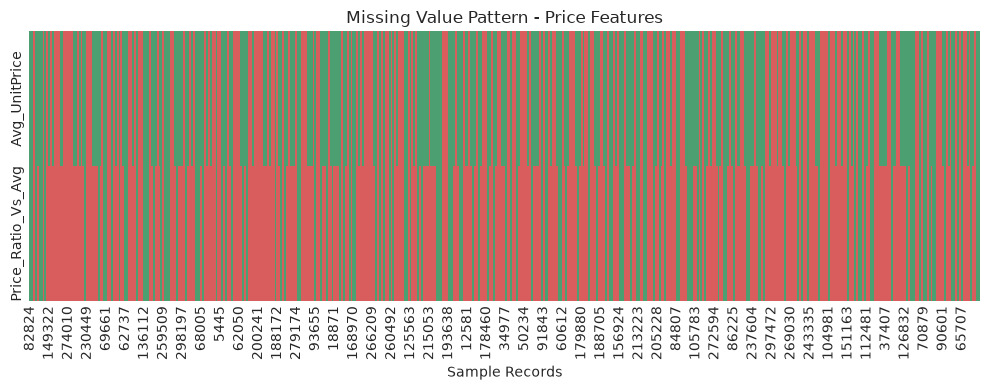

In [15]:
missing_data = (
    df_gold.select([
        pl.col("Avg_UnitPrice").is_null().cast(pl.Int8).alias("Avg_UnitPrice"),
        pl.col("Price_Ratio_Vs_Avg").is_null().cast(pl.Int8).alias("Price_Ratio_Vs_Avg")
    ])
    .to_pandas()
)

plt.figure(figsize=(10, 4))
sns.heatmap(
    missing_data.sample(min(500, len(missing_data)), random_state=42).T,
    cbar=False,
    cmap=["#4C9F70", "#D95D5D"],
    yticklabels=True
)
plt.title("Missing Value Pattern - Price Features")
plt.xlabel("Sample Records")
plt.tight_layout()
plt.show()

In [18]:
# ============================================================
# ROW-LEVEL MISSING VALIDATION
# ============================================================

display(df_gold.select([
    (
        (pl.col("Weekly_Demand") == 0) &
        pl.col("Avg_UnitPrice").is_null()
    ).sum().alias("ZeroDemand_And_PriceNull"),

    (
        (pl.col("Weekly_Demand") != 0) &
        pl.col("Avg_UnitPrice").is_null()
    ).sum().alias("NonZeroDemand_And_PriceNull"),

    (
        (pl.col("Weekly_Demand") == 0) &
        pl.col("Avg_UnitPrice").is_not_null()
    ).sum().alias("ZeroDemand_And_PriceAvailable"),

    (
        (pl.col("Weekly_Demand") > 0) &
        pl.col("Avg_UnitPrice").is_not_null()
    ).sum().alias("PositiveDemand_And_PriceAvailable")
]))

ZeroDemand_And_PriceNull,NonZeroDemand_And_PriceNull,ZeroDemand_And_PriceAvailable,PositiveDemand_And_PriceAvailable
u32,u32,u32,u32
123122,0,0,178509


In [19]:
# ============================================================
# RATIO MISSING DIAGNOSIS
# ============================================================

ratio_missing = df_gold.filter(
    pl.col("Avg_UnitPrice").is_not_null() &
    pl.col("Price_Ratio_Vs_Avg").is_null()
)

display(ratio_missing.select([
    pl.len().alias("Total_Ratio_Missing"),
    pl.col("Weekly_Demand").mean().alias("Mean_Demand"),
    pl.col("Avg_UnitPrice").mean().alias("Mean_Price"),
    pl.col("Avg_UnitPrice").min().alias("Min_Price"),
    pl.col("Avg_UnitPrice").max().alias("Max_Price")
]))

display(
    ratio_missing.group_by("Year")
    .agg([
        pl.len().alias("Ratio_Missing_Count"),
        pl.col("StockCode").n_unique().alias("Affected_SKUs")
    ])
    .sort("Year")
)

Total_Ratio_Missing,Mean_Demand,Mean_Price,Min_Price,Max_Price
u32,f64,f64,f64,f64
79720,27.463886,4.071614,0.001,13541.33


Year,Ratio_Missing_Count,Affected_SKUs
i32,u32,u32
2010,41864,3463
2011,37856,3216


4. Tìm nguyên nhân 79,720 Ratio Missing

In [20]:
# ============================================================
# RATIO MISSING BY SKU
# ============================================================

ratio_sku_audit = (
    df_gold.filter(pl.col("Avg_UnitPrice").is_not_null())
    .group_by("StockCode")
    .agg([
        pl.len().alias("Price_Available_Weeks"),
        pl.col("Price_Ratio_Vs_Avg").null_count().alias("Ratio_Missing_Weeks"),
        pl.col("Avg_UnitPrice").mean().alias("Mean_Price")
    ])
    .with_columns(
        (pl.col("Ratio_Missing_Weeks") /
         pl.col("Price_Available_Weeks") * 100)
        .alias("Ratio_Missing_Rate")
    )
    .sort("Ratio_Missing_Rate", descending=True)
)

display(ratio_sku_audit.head(20))

StockCode,Price_Available_Weeks,Ratio_Missing_Weeks,Mean_Price,Ratio_Missing_Rate
str,u32,u32,f64,f64
"""90020""",2,2,12.75,100.0
"""84526""",21,21,2.140635,100.0
"""84966A""",1,1,20.0,100.0
"""47469""",21,21,0.628095,100.0
"""47586A""",21,21,2.404286,100.0
…,…,…,…,…
"""20825""",3,3,3.63,100.0
"""21309""",1,1,6.0,100.0
"""35004P""",13,13,5.891381,100.0


In [21]:
# ============================================================
# RATIO MISSING BY WEEK
# ============================================================

ratio_week_audit = (
    df_gold.filter(pl.col("Avg_UnitPrice").is_not_null())
    .group_by("Week_Start")
    .agg([
        pl.len().alias("Total_Price_Records"),
        pl.col("Price_Ratio_Vs_Avg").null_count().alias("Ratio_Null")
    ])
    .with_columns(
        (pl.col("Ratio_Null") /
         pl.col("Total_Price_Records") * 100)
        .alias("Missing_Rate")
    )
    .sort("Week_Start")
)

display(ratio_week_audit.sort("Missing_Rate", descending=True).head(15))

Week_Start,Total_Price_Records,Ratio_Null,Missing_Rate
datetime[μs],u32,u32,f64
2010-01-04 00:00:00,1343,1343,100.0
2010-01-11 00:00:00,1850,1850,100.0
2010-01-18 00:00:00,1805,1805,100.0
2010-01-25 00:00:00,1734,1734,100.0
2011-01-03 00:00:00,1788,1788,100.0
…,…,…,…
2010-04-19 00:00:00,1796,867,48.273942
2010-08-16 00:00:00,1799,866,48.137854
2010-09-13 00:00:00,1822,875,48.024149


In [22]:
# ============================================================
# EXTREME PRICE INVESTIGATION
# ============================================================

price_extremes = (
    df_gold.filter(pl.col("Avg_UnitPrice").is_not_null())
    .sort("Avg_UnitPrice", descending=True)
    .select([
        "Week_Start",
        "StockCode",
        "Description",
        "Weekly_Demand",
        "Weekly_Revenue",
        "Avg_UnitPrice",
        "Price_Ratio_Vs_Avg"
    ])
    .head(20)
)

display(price_extremes)

Week_Start,StockCode,Description,Weekly_Demand,Weekly_Revenue,Avg_UnitPrice,Price_Ratio_Vs_Avg
datetime[μs],str,str,i64,f64,f64,f64
2010-12-06 00:00:00,"""AMAZONFEE""","""AMAZON FEE""",2,27082.66,13541.33,null
2010-06-14 00:00:00,"""M""","""Manual""",211,34597.78,3127.456364,15.585398
2010-01-25 00:00:00,"""M""","""Manual""",3,9035.55,3011.85,null
2010-10-04 00:00:00,"""M""","""Manual""",24,31488.71,1368.963478,1.940565
2010-09-27 00:00:00,"""M""","""Manual""",18,22885.8,1346.212353,2.785941
…,…,…,…,…,…,…
2011-11-14 00:00:00,"""DOT""","""DOTCOM POSTAGE""",10,8669.46,866.946,1.707156
2011-08-22 00:00:00,"""DOT""","""DOTCOM POSTAGE""",2,1634.75,817.375,1.54721
2010-03-15 00:00:00,"""M""","""Manual""",300,22721.73,805.171429,14.939389


In [23]:
price_validation = (
    df_gold.filter(pl.col("Weekly_Demand") > 0)
    .with_columns(
        (pl.col("Weekly_Revenue") /
         pl.col("Weekly_Demand")).alias("Calculated_Price")
    )
    .with_columns(
        (pl.col("Avg_UnitPrice") -
         pl.col("Calculated_Price")).abs().alias("Price_Difference")
    )
)

display(price_validation.select([
    pl.col("Price_Difference").mean().alias("Mean_Difference"),
    pl.col("Price_Difference").median().alias("Median_Difference"),
    pl.col("Price_Difference").max().alias("Max_Difference"),
    (pl.col("Price_Difference") > 0.01).sum().alias("Mismatch_Count")
]))

Mean_Difference,Median_Difference,Max_Difference,Mismatch_Count
f64,f64,f64,u32
0.282802,0.0,2963.485842,73442


In [24]:
# ============================================================
# INVESTIGATION: AVG UNIT PRICE VALIDATION
# ============================================================

price_validation = (
    df_gold.filter(
        (pl.col("Weekly_Demand") > 0) &
        pl.col("Avg_UnitPrice").is_not_null()
    )
    .with_columns(
        (pl.col("Weekly_Revenue") / pl.col("Weekly_Demand"))
        .alias("Revenue_Per_Unit")
    )
    .with_columns([
        (pl.col("Avg_UnitPrice") - pl.col("Revenue_Per_Unit"))
        .abs().alias("Absolute_Difference"),

        (
            (pl.col("Avg_UnitPrice") - pl.col("Revenue_Per_Unit")).abs() /
            pl.col("Revenue_Per_Unit").abs().clip(lower_bound=0.000001)
            * 100
        ).alias("Relative_Difference_Pct")
    ])
)

display(
    price_validation.sort("Absolute_Difference", descending=True)
    .select([
        "Week_Start", "StockCode", "Description",
        "Weekly_Demand", "Weekly_Revenue",
        "Avg_UnitPrice", "Revenue_Per_Unit",
        "Absolute_Difference", "Relative_Difference_Pct"
    ])
    .head(20)
)

Week_Start,StockCode,Description,Weekly_Demand,Weekly_Revenue,Avg_UnitPrice,Revenue_Per_Unit,Absolute_Difference,Relative_Difference_Pct
datetime[μs],str,str,i64,f64,f64,f64,f64,f64
2010-06-14 00:00:00,"""M""","""Manual""",211,34597.78,3127.456364,163.970521,2963.485842,1807.328426
2010-09-13 00:00:00,"""M""","""Manual""",38,13570.46,1232.495455,357.117368,875.378086,245.123358
2010-04-19 00:00:00,"""M""","""Manual""",49,11881.57,987.95,242.48102,745.46898,307.43395
2010-03-22 00:00:00,"""M""","""Manual""",242,31468.72,869.992778,130.036033,739.956745,569.039771
2010-03-15 00:00:00,"""M""","""Manual""",300,22721.73,805.171429,75.7391,729.432329,963.085551
…,…,…,…,…,…,…,…,…
2010-12-20 00:00:00,"""M""","""Manual""",21,1326.55,330.7875,63.169048,267.618452,423.654404
2010-07-26 00:00:00,"""M""","""Manual""",35,4524.75,374.283333,129.278571,245.004762,189.516916
2010-10-25 00:00:00,"""M""","""Manual""",16,3934.01,490.06375,245.875625,244.188125,99.313677


In [25]:
# ============================================================
# SPECIAL SKU AUDIT
# ============================================================

special_keywords = [
    "AMAZONFEE", "M", "DOT"
]

special_sku_audit = (
    df_gold.filter(pl.col("StockCode").is_in(special_keywords))
    .group_by(["StockCode", "Description"])
    .agg([
        pl.len().alias("Total_Weeks"),
        pl.col("Weekly_Demand").sum().alias("Total_Demand"),
        pl.col("Weekly_Revenue").sum().alias("Total_Revenue"),
        pl.col("Target_Demand_Weekly").sum().alias("Total_Target"),
        pl.col("Avg_UnitPrice").max().alias("Max_Price")
    ])
)

display(special_sku_audit)

StockCode,Description,Total_Weeks,Total_Demand,Total_Revenue,Total_Target,Max_Price
str,str,u32,i64,f64,i64,f64
"""DOT""","""DOTCOM POSTAGE""",101,1374,286415.36,1387,1154.67
"""AMAZONFEE""","""AMAZON FEE""",16,2,27082.66,1,13541.33
"""M""","""Manual""",101,9221,338066.48,10031,3127.456364


In [26]:
# ============================================================
# RATIO MISSING BY MONTH
# ============================================================

ratio_calendar_audit = (
    df_gold.filter(pl.col("Avg_UnitPrice").is_not_null())
    .group_by(["Year", "Month"])
    .agg([
        pl.len().alias("Total_Rows"),
        pl.col("Price_Ratio_Vs_Avg").null_count().alias("Ratio_Null")
    ])
    .with_columns(
        (pl.col("Ratio_Null") / pl.col("Total_Rows") * 100)
        .alias("Missing_Rate")
    )
    .sort(["Year", "Month"])
)

display(ratio_calendar_audit)

Year,Month,Total_Rows,Ratio_Null,Missing_Rate
i32,i8,u32,u32,f64
2010,1,6732,6732,100.0
2010,2,6688,2935,43.884569
2010,3,8913,3895,43.700213
2010,4,6630,2982,44.977376
2010,5,8593,3683,42.860468
…,…,…,…,…
2011,7,7663,3251,42.424638
2011,8,8828,3446,39.034889
2011,9,7745,3192,41.213686


In [27]:
# ============================================================
# MISMATCH ANALYSIS BY SKU
# ============================================================

mismatch_by_sku = (
    price_validation.group_by(["StockCode", "Description"])
    .agg([
        pl.len().alias("Total_Records"),
        (pl.col("Absolute_Difference") > 0.01)
            .sum().alias("Mismatch_Count"),
        pl.col("Absolute_Difference").mean().alias("Mean_Difference"),
        pl.col("Relative_Difference_Pct").median().alias("Median_Relative_Diff")
    ])
    .with_columns(
        (pl.col("Mismatch_Count") / pl.col("Total_Records") * 100)
        .alias("Mismatch_Rate")
    )
    .sort("Mismatch_Count", descending=True)
)

display(mismatch_by_sku.head(30))

StockCode,Description,Total_Records,Mismatch_Count,Mean_Difference,Median_Relative_Diff,Mismatch_Rate
str,str,u32,u32,f64,f64,f64
"""21931""","""JUMBO STORAGE BAG SUKI""",99,99,0.423851,18.538535,100.0
"""85099C""","""JUMBO BAG BAROQUE BLACK WHITE""",99,99,0.429982,18.148442,100.0
"""POST""","""POSTAGE""",99,98,7.253819,5.347424,98.989899
"""85123A""","""WHITE HANGING HEART T-LIGHT HO…",99,98,0.370925,12.671213,98.989899
"""84991""","""60 TEATIME FAIRY CAKE CASES""",99,97,0.147061,25.212528,97.979798
…,…,…,…,…,…,…
"""47566""","""PARTY BUNTING""",98,92,0.603195,9.912051,93.877551
"""84992""","""72 SWEETHEART FAIRY CAKE CASES""",99,92,0.150414,26.199045,92.929293
"""21218""","""RED SPOTTY BISCUIT TIN""",99,91,0.969003,20.545707,91.919192


In [28]:
display(
    mismatch_by_sku.select([
        pl.len().alias("Total_SKUs"),
        pl.col("Total_Records").sum().alias("Total_Records"),
        pl.col("Mismatch_Count").sum().alias("Total_Mismatches"),
        pl.col("Mismatch_Rate").median().alias("Median_SKU_Mismatch_Rate")
    ])
)

Total_SKUs,Total_Records,Total_Mismatches,Median_SKU_Mismatch_Rate
u32,u32,u32,f64
4803,178509,73442,25.0


In [29]:
special_codes = ["M", "DOT", "AMAZONFEE"]

display(
    mismatch_by_sku.filter(
        pl.col("StockCode").is_in(special_codes)
    )
)

StockCode,Description,Total_Records,Mismatch_Count,Mean_Difference,Median_Relative_Diff,Mismatch_Rate
str,str,u32,u32,f64,f64,f64
"""M""","""Manual""",99,87,138.828199,127.7847,87.878788
"""AMAZONFEE""","""AMAZON FEE""",1,0,0.0,0.0,0.0
"""DOT""","""DOTCOM POSTAGE""",98,0,0.0,0.0,0.0


In [30]:
# ============================================================
# PRICE RATIO MISSING DISTRIBUTION
# ============================================================

ratio_missing_sample = (
    df_gold.filter(
        pl.col("Avg_UnitPrice").is_not_null() &
        pl.col("Price_Ratio_Vs_Avg").is_null()
    )
    .select([
        "Week_Start",
        "Year",
        "Month",
        "StockCode",
        "Avg_UnitPrice",
        "Price_Ratio_Vs_Avg"
    ])
    .sort(["StockCode", "Week_Start"])
)

display(ratio_missing_sample.head(30))

Week_Start,Year,Month,StockCode,Avg_UnitPrice,Price_Ratio_Vs_Avg
datetime[μs],i32,i8,str,f64,f64
2010-01-04 00:00:00,2010,1,"""10002""",0.85,null
2010-01-11 00:00:00,2010,1,"""10002""",0.85,null
2010-01-18 00:00:00,2010,1,"""10002""",1.012,null
2010-01-25 00:00:00,2010,1,"""10002""",0.985,null
2011-01-03 00:00:00,2011,1,"""10002""",1.12,null
…,…,…,…,…,…
2011-11-07 00:00:00,2011,11,"""10080""",0.39,null
2011-11-14 00:00:00,2011,11,"""10080""",0.39,null
2010-01-04 00:00:00,2010,1,"""10120""",0.21,null


In [34]:
sku_history = (
    df_gold.filter(pl.col("StockCode") == "10002")
    .sort("Week_Start")
    .with_columns([
        pl.col("Avg_UnitPrice").shift(1).alias("Previous_Week_Price"),
        (
            pl.col("Avg_UnitPrice").fill_null(0).cum_sum().shift(1) /
            pl.col("Avg_UnitPrice").is_not_null().cast(pl.Int64).cum_sum().shift(1)
        ).alias("Historical_Avg_Price")
    ])
    .select([
        "Week_Start", "Weekly_Demand", "Avg_UnitPrice",
        "Previous_Week_Price", "Historical_Avg_Price",
        "Price_Ratio_Vs_Avg"
    ])
)
display(sku_history)

Week_Start,Weekly_Demand,Avg_UnitPrice,Previous_Week_Price,Historical_Avg_Price,Price_Ratio_Vs_Avg
datetime[μs],i64,f64,f64,f64,f64
2009-12-28 00:00:00,0,null,null,null,null
2010-01-04 00:00:00,15,0.85,null,NaN,null
2010-01-11 00:00:00,191,0.85,0.85,0.85,null
2010-01-18 00:00:00,41,1.012,0.85,0.85,null
2010-01-25 00:00:00,44,0.985,1.012,0.904,null
…,…,…,…,…,…
2011-03-14 00:00:00,11,1.11,1.63,0.993984,0.872292
2011-03-21 00:00:00,11,0.85,1.11,0.995856,0.703928
2011-03-28 00:00:00,126,0.85,0.85,0.99354,0.703928


In [33]:
ratio_root_cause = (
    df_gold.sort(["StockCode", "Week_Start"])
    .group_by("StockCode")
    .agg([
        pl.len().alias("Total_Weeks"),
        pl.col("Avg_UnitPrice").count().alias("Price_Weeks"),
        pl.col("Price_Ratio_Vs_Avg").count().alias("Valid_Ratio_Weeks"),
        pl.col("Price_Ratio_Vs_Avg").null_count().alias("Null_Ratio_Weeks")
    ])
    .with_columns(
        (pl.col("Null_Ratio_Weeks") / pl.col("Total_Weeks") * 100)
        .alias("Ratio_Missing_Rate")
    )
    .sort("Ratio_Missing_Rate", descending=True)
)

display(ratio_root_cause.head(30))

StockCode,Total_Weeks,Price_Weeks,Valid_Ratio_Weeks,Null_Ratio_Weeks,Ratio_Missing_Rate
str,u32,u32,u32,u32,f64
"""10002R""",4,0,0,4,100.0
"""10080""",99,18,0,99,100.0
"""10120""",100,37,0,100,100.0
"""10124A""",81,13,0,81,100.0
"""10124G""",73,6,0,73,100.0
…,…,…,…,…,…
"""16201A""",36,5,0,36,100.0
"""16202A""",67,15,0,67,100.0
"""16202B""",68,18,0,68,100.0


In [35]:
df_ratio_check = (
    df_gold.filter(
        (pl.col("StockCode") == "10002") &
        pl.col("Avg_UnitPrice").is_not_null() &
        pl.col("Price_Ratio_Vs_Avg").is_not_null()
    )
    .with_columns([
        (pl.col("Avg_UnitPrice") / pl.col("Price_Ratio_Vs_Avg")).alias("Implied_Benchmark_1"),
        (pl.col("Avg_UnitPrice") * pl.col("Price_Ratio_Vs_Avg")).alias("Implied_Benchmark_2")
    ])
    .select([
        "Week_Start", "Avg_UnitPrice", "Price_Ratio_Vs_Avg",
        "Implied_Benchmark_1", "Implied_Benchmark_2"
    ])
)
display(df_ratio_check)

Week_Start,Avg_UnitPrice,Price_Ratio_Vs_Avg,Implied_Benchmark_1,Implied_Benchmark_2
datetime[μs],f64,f64,f64,f64
2010-02-01 00:00:00,1.12,1.21178,0.92426,1.357194
2010-02-08 00:00:00,0.85,0.857062,0.99176,0.728503
2010-02-15 00:00:00,1.0525,1.061245,0.99176,1.11696
2010-02-22 00:00:00,0.85,0.848401,1.001885,0.721141
2010-03-01 00:00:00,0.91875,0.94899,0.968135,0.871884
…,…,…,…,…
2011-02-28 00:00:00,1.24,1.265293,0.98001,1.568964
2011-03-07 00:00:00,1.63,1.512747,1.07751,2.465778
2011-03-14 00:00:00,1.11,0.872292,1.27251,0.968244
